#Imports

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from keras.models import Sequential, model_from_json
from keras.layers import Dense
from keras.optimizers import Adam,RMSprop
from keras.utils import to_categorical
from keras.layers import Dropout, Flatten
from keras.layers import Conv2D, MaxPooling2D, AveragePooling2D
from tensorflow.keras import regularizers
import cv2
from sklearn.model_selection import train_test_split
import pickle
import os
import pandas as pd
import random
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import plot_model
from tensorflow import keras
from tensorflow.keras import layers
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import optimizers
import time
import warnings
warnings.filterwarnings('ignore')
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, f1_score
from torchvision import transforms as T
from PIL import Image
from google.colab.patches import cv2_imshow
from scipy.ndimage import label
from zipfile import ZipFile
from tqdm import tqdm
from mpl_toolkits.mplot3d import Axes3D
import torch.nn.functional as F_torch
import math
import random
from IPython.display import display
from scipy.ndimage import label, center_of_mass
from scipy.optimize import linear_sum_assignment
from skimage.measure import label, regionprops
import matplotlib.patches as patches
from torch.optim.swa_utils import AveragedModel
import time
from sklearn.metrics import roc_curve, auc
from scipy.ndimage import label
from matplotlib.patches import Rectangle

#Device Check

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


#Extract Dataset

In [ ]:
with ZipFile('/content/IRSTD-1k-20260709T092039Z-3-001.zip', 'r') as zipObj:
   zipObj.extractall()

# Image And Mask Load

In [ ]:
import os
import cv2
import numpy as np

image_path = "/content/IRSTD-1k/IRSTD-1k test/images"
mask_path = "/content/IRSTD-1k/IRSTD-1k test/masks"

selected_files = [
    "XDU689.png",
    "XDU296.png"
]

images = []
masks = []

for file in selected_files:

    img = cv2.imread(
        os.path.join(image_path, file),
        0
    )

    mask = cv2.imread(
        os.path.join(mask_path, file),
        0
    )

    images.append(img)
    masks.append(mask)

X_test = np.array(images)
y_test = np.array(masks)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_test shape: (2, 512, 512)
y_test shape: (2, 512, 512)


#Splitting Train,Validation And Test Set

#CustomDataset Load

In [ ]:
normal_transform = T.Compose([
    T.ToTensor()
])

In [ ]:
class CustomDataset(Dataset):

    def __init__(self, features, masks,
                 image_transform=None,
                 mask_transform=None):

        self.features = features
        self.masks = masks

        self.image_transform = image_transform
        self.mask_transform = mask_transform

    def __len__(self):
        return len(self.features)

    def __getitem__(self, index):

        image = self.features[index]
        mask = self.masks[index]

        image = image.astype(np.uint8)
        mask = mask.astype(np.uint8)

        image = Image.fromarray(image)
        mask = Image.fromarray(mask)


        if self.image_transform:
            image = self.image_transform(image)

        if self.mask_transform:
            mask = self.mask_transform(mask)

        return image, mask

In [ ]:
test_dataset = CustomDataset(X_test,y_test, image_transform=normal_transform,mask_transform=normal_transform)

In [ ]:
testloader = DataLoader(test_dataset,batch_size=1,shuffle=False,pin_memory=True)

In [ ]:
len(testloader)

2

In [ ]:
n = len(testloader)

image_tensors = []
mask_tensors = []

for _ in range(3):
    random_index = random.randint(0, n - 1)
    random_sample = testloader.dataset[random_index]

    image_tensors.append(random_sample[0])
    mask_tensors.append(random_sample[1])

#Feature map Inference

In [ ]:
def compare_models_3d(image_tensors,mask_tensors,model_paths,model_names,model_channels,device="cuda",num_images=6):

    # ==========================================================
    # 1. LOAD ALL MODELS
    # ==========================================================
    models = []

    for path in model_paths:

        model = torch.jit.load(path,map_location=device)

        model.eval()

        models.append(model)


    # ==========================================================
    # 2. FIGURE SETUP
    # ==========================================================
    num_images = min(num_images,len(image_tensors))

    # Input + GT + all models
    num_cols = len(models) + 2

    fig = plt.figure(figsize=(4 * num_cols,3.5 * num_images))


    # ==========================================================
    # 3. LOOP THROUGH TEST IMAGES
    # ==========================================================
    for row in range(num_images):

        image_tensor = image_tensors[row]
        mask_tensor = mask_tensors[row]


        # [1,H,W] -> [H,W]
        image = image_tensor[0]


        # ======================================================
        # 3.1 INPUT IMAGE
        # ======================================================
        img = (image.detach().cpu().numpy())

        H, W = img.shape

        X, Y = np.meshgrid(np.arange(W),np.arange(H))


        # Column 1
        plot_position = (row * num_cols+ 1)


        ax = fig.add_subplot(num_images,num_cols,plot_position,projection="3d")


        ax.plot_surface(X,Y,img,cmap="jet",linewidth=0,antialiased=True)


        # ------------------------------------------------------
        # INPUT COLUMN HEADING
        # ------------------------------------------------------
        if row == 0:

            ax.set_title("Input Image",fontsize=15,fontweight="light",pad=15)

        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_zticks([])



        # ======================================================
        # 3.2 GROUND TRUTH
        # ======================================================
        mask = (mask_tensor[0].detach().cpu().numpy())


        H_gt, W_gt = mask.shape


        X_gt, Y_gt = np.meshgrid(np.arange(W_gt),np.arange(H_gt))


        # Column 2
        plot_position = (row * num_cols + 2)


        ax = fig.add_subplot(
            num_images,
            num_cols,
            plot_position,
            projection="3d"
        )


        ax.plot_surface(
            X_gt,
            Y_gt,
            mask,
            cmap="jet",
            linewidth=0,
            antialiased=True
        )


        # ------------------------------------------------------
        # GT COLUMN HEADING
        # ------------------------------------------------------
        if row == 0:

            ax.set_title(
                "Ground Truth",
                fontsize=15,
                fontweight="light",
                pad=15
            )


        ax.set_zlim(
            0,
            1
        )


        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_zticks([])



        # ======================================================
        # 3.3 MODEL PREDICTIONS
        # ======================================================
        for model_idx, (
            model,
            required_channels
        ) in enumerate(
            zip(
                models,
                model_channels
            )
        ):


            # ==================================================
            # PREPARE MODEL INPUT
            # ==================================================

            # --------------------------------------------------
            # 1-channel model
            # --------------------------------------------------
            if required_channels == 1:

                x_input = (
                    image
                    .unsqueeze(0)
                    .unsqueeze(0)
                    .to(device)
                )


            # --------------------------------------------------
            # 3-channel model
            # --------------------------------------------------
            elif required_channels == 3:

                image_3ch = (
                    image
                    .unsqueeze(0)
                    .repeat(
                        3,
                        1,
                        1
                    )
                )


                x_input = (
                    image_3ch
                    .unsqueeze(0)
                    .to(device)
                )


            else:

                raise ValueError(
                    f"Unsupported number of channels: "
                    f"{required_channels}"
                )



            # ==================================================
            # FORWARD PASS
            # ==================================================
            with torch.no_grad():

                output = model(
                    x_input
                )



            # ==================================================
            # HANDLE MULTIPLE OUTPUTS
            # ==================================================
            if isinstance(
                output,
                (tuple, list)
            ):

                # Assume first output is main prediction
                output = output[0]



            # ==================================================
            # LOGITS -> PROBABILITY
            # ==================================================
            pred = torch.sigmoid(
                output
            )


            # [B,1,H,W] -> [H,W]
            if pred.ndim == 4:

                pred = pred[0, 0]


            # [B,H,W] -> [H,W]
            elif pred.ndim == 3:

                pred = pred[0]


            pred = (
                pred
                .detach()
                .cpu()
                .numpy()
            )



            # ==================================================
            # CREATE 3D PREDICTION
            # ==================================================
            H_pred, W_pred = pred.shape


            X_pred, Y_pred = np.meshgrid(
                np.arange(W_pred),
                np.arange(H_pred)
            )


            # --------------------------------------------------
            # Models start from Column 3
            #
            # model_idx = 0 -> column 3
            # model_idx = 1 -> column 4
            # model_idx = 2 -> column 5
            # --------------------------------------------------
            plot_position = (
                row * num_cols
                + model_idx
                + 3
            )


            ax = fig.add_subplot(
                num_images,
                num_cols,
                plot_position,
                projection="3d"
            )


            ax.plot_surface(
                X_pred,
                Y_pred,
                pred,
                cmap="jet",
                linewidth=0,
                antialiased=True
            )


            # --------------------------------------------------
            # MODEL NAME AS COLUMN HEADING
            # --------------------------------------------------
            if row == 0:

                ax.set_title(
                    model_names[model_idx],
                    fontsize=15,
                    fontweight="light",
                    pad=15
                )


            ax.set_zlim(
                0,
                1
            )


            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_zticks([])



    # ==========================================================
    # 4. SPACING
    # ==========================================================
    plt.subplots_adjust(
        left=0.07,
        right=0.99,
        bottom=0.02,
        top=0.92,
        wspace=0.02,
        hspace=0.08
    )



    # ==========================================================
    # 5. ADD "SAMPLE 1", "SAMPLE 2", ...
    # ==========================================================

    # Actual subplot area
    plot_bottom = 0.02
    plot_top = 0.92


    plot_height = (
        plot_top
        - plot_bottom
    )


    row_height = (
        plot_height
        / num_images
    )


    for row in range(num_images):

        # Center position of current row
        y_center = (
            plot_top
            - (row + 0.5)
            * row_height
        )


        fig.text(
            0.012,
            y_center,
            f"Image {row + 1}",
            fontsize=13,
            fontweight="bold",
            va="center",
            ha="left"
        )



    # ==========================================================
    # 6. DOTTED LINES BETWEEN SAMPLES
    # ==========================================================
    for row in range(
        1,
        num_images
    ):

        # Boundary between two rows
        y_line = (
            plot_top
            - row
            * row_height
        )


        separator = plt.Line2D(
            [0.055, 0.99],
            [y_line, y_line],
            transform=fig.transFigure,
            linestyle=":",
            linewidth=5,
            alpha=0.7
        )


        fig.add_artist(
            separator
        )



    # ==========================================================
    # 7. SHOW
    # ==========================================================
    plt.show()

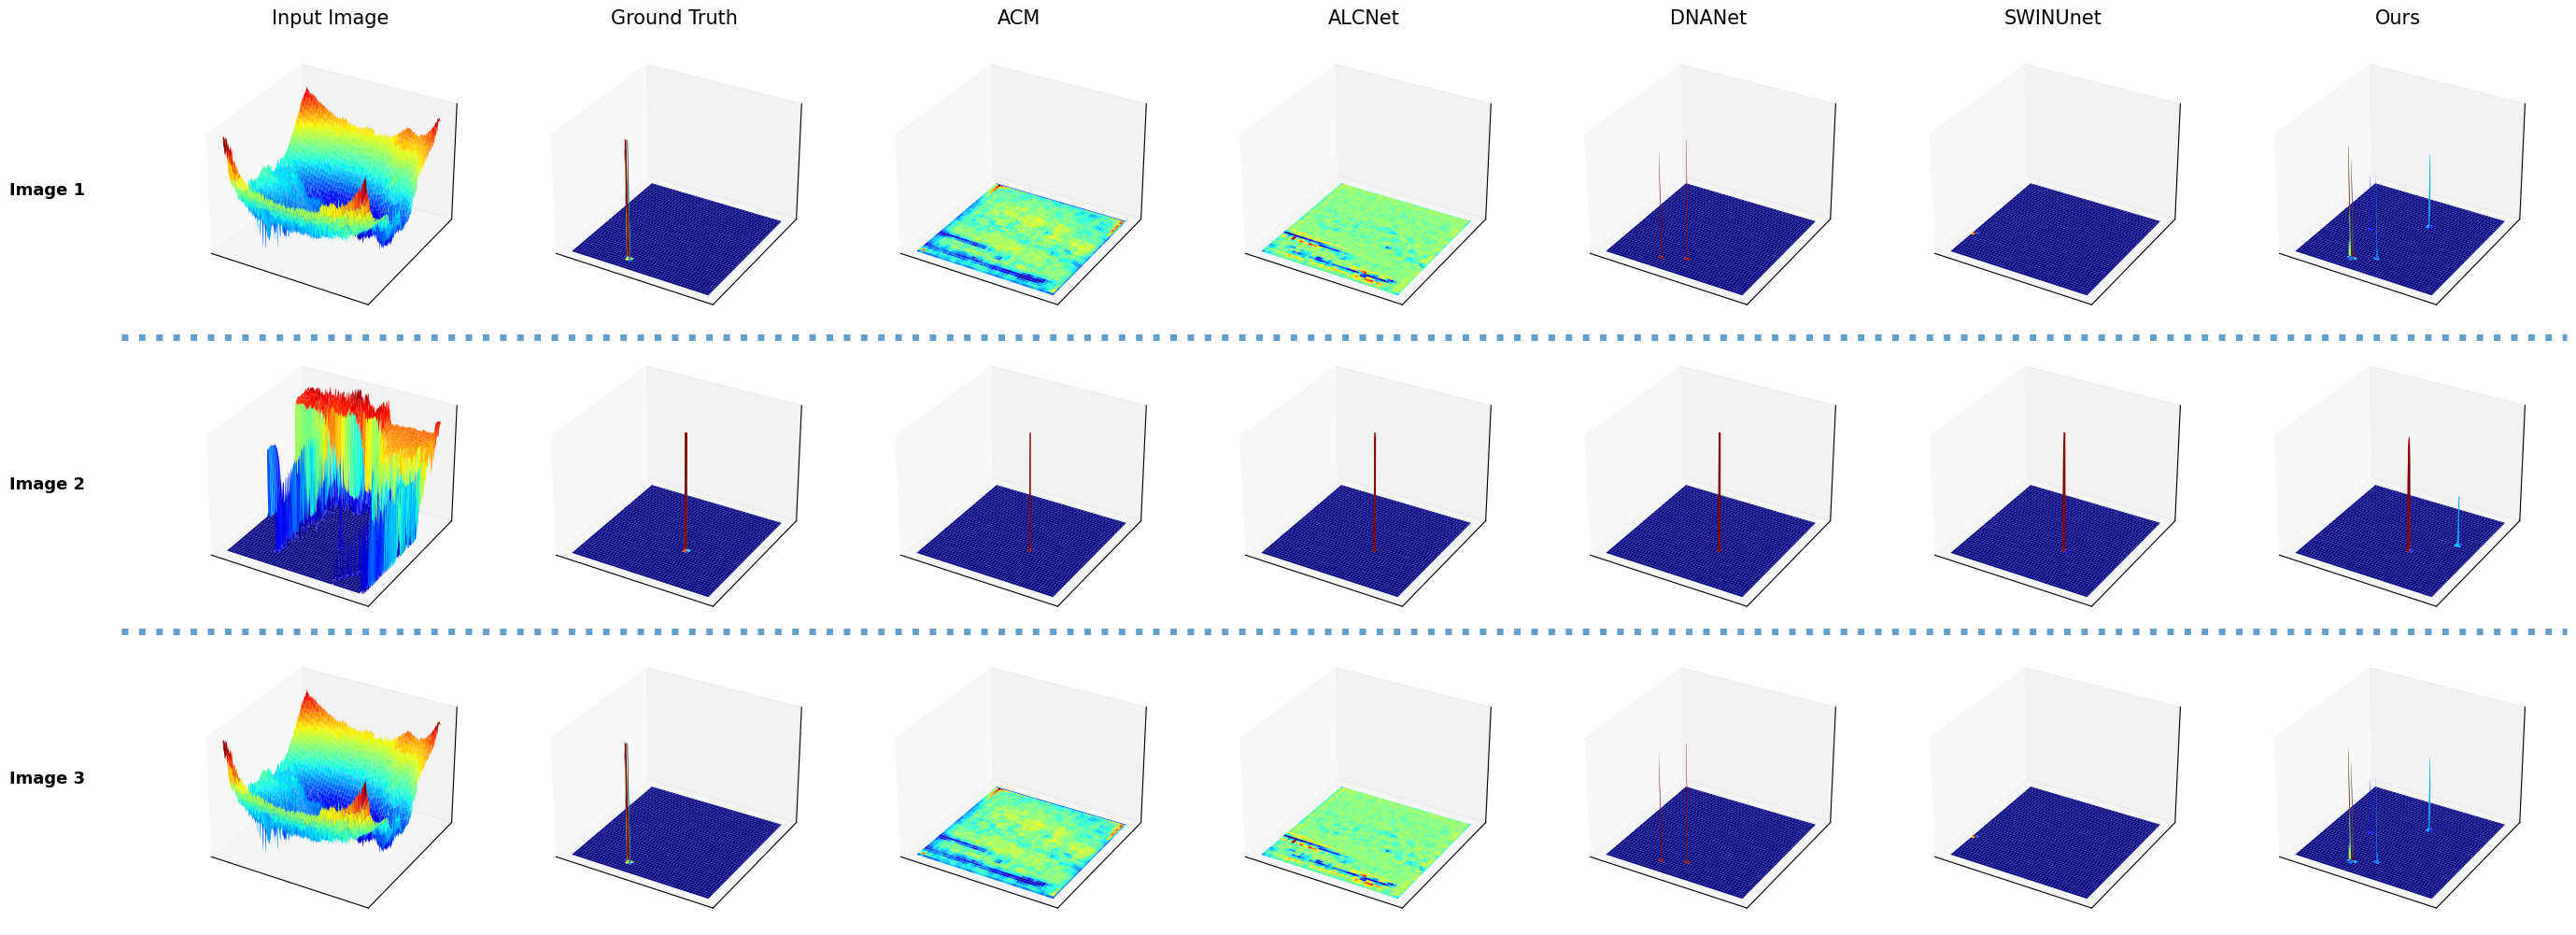

In [ ]:
model_paths = ["/content/ACM.pt","/content/ALCNet.pt","/content/DNA-NET.pt","/content/SWIN-UNET.pt","/content/Ours.pt"]

model_names = ["ACM","ALCNet","DNANet","SWINUnet","Ours"]

model_channels = [3,3,1,1,1]


compare_models_3d(image_tensors=image_tensors,mask_tensors=mask_tensors,model_paths=model_paths,
    model_names=model_names,
    model_channels=model_channels,
    device="cuda",
    num_images=3
)

#2d images

In [ ]:
# ============================================================
# 1. GET CONNECTED COMPONENTS
# ============================================================
def get_components(binary_mask, min_area=1):

    """
    Extract connected components from a binary mask.

    Returns:
        centroid
        bounding box
        area
    """

    binary_mask = (binary_mask > 0).astype(np.uint8)

    # 8-connectivity
    structure = np.ones((3, 3), dtype=np.uint8)

    labeled_mask, num_components = label(
        binary_mask,
        structure=structure
    )

    components = []

    for component_id in range(1, num_components + 1):

        ys, xs = np.where(
            labeled_mask == component_id
        )

        # Ignore very small components if required
        if len(xs) < min_area:
            continue


        # ======================================================
        # CENTROID
        # ======================================================
        centroid_x = xs.mean()
        centroid_y = ys.mean()


        # ======================================================
        # BOUNDING BOX
        # ======================================================
        x_min = xs.min()
        x_max = xs.max()

        y_min = ys.min()
        y_max = ys.max()


        components.append(
            {
                "centroid": (
                    centroid_x,
                    centroid_y
                ),

                "bbox": (
                    x_min,
                    y_min,
                    x_max,
                    y_max
                ),

                "area": len(xs)
            }
        )


    return components



# ============================================================
# 2. MATCH PREDICTIONS TO GROUND TRUTH
# ============================================================
def match_predictions_to_gt(
    pred_components,
    gt_components,
    max_distance=3
):

    """
    Match predicted components with GT components
    based on centroid distance.

    Green box:
        Correct detection

    Red box:
        False alarm
    """

    matched_gt = set()

    results = []


    for pred_component in pred_components:

        pred_x, pred_y = pred_component["centroid"]

        best_distance = float("inf")
        best_gt_idx = None


        # ======================================================
        # FIND NEAREST UNUSED GT TARGET
        # ======================================================
        for gt_idx, gt_component in enumerate(gt_components):

            # Prevent one GT target from matching
            # multiple predictions
            if gt_idx in matched_gt:
                continue


            gt_x, gt_y = gt_component["centroid"]


            distance = np.sqrt(
                (pred_x - gt_x) ** 2
                +
                (pred_y - gt_y) ** 2
            )


            if distance < best_distance:

                best_distance = distance
                best_gt_idx = gt_idx


        # ======================================================
        # CORRECT DETECTION
        # ======================================================
        if (
            best_gt_idx is not None
            and
            best_distance <= max_distance
        ):

            matched_gt.add(best_gt_idx)

            results.append(
                {
                    "component": pred_component,
                    "status": "true",
                    "distance": best_distance
                }
            )


        # ======================================================
        # FALSE ALARM
        # ======================================================
        else:

            results.append(
                {
                    "component": pred_component,
                    "status": "false",
                    "distance": None
                }
            )


    return results



# ============================================================
# 3. DRAW BOUNDING BOX
# ============================================================
def draw_bbox(
    ax,
    bbox,
    color,
    padding=4,
    linewidth=2
):

    """
    Draw a bounding box around a target.
    """

    x_min, y_min, x_max, y_max = bbox


    # Add padding so very small IR targets
    # are easier to see
    new_x_min = x_min - padding
    new_y_min = y_min - padding


    width = (
        x_max
        - x_min
        + 2 * padding
        + 1
    )


    height = (
        y_max
        - y_min
        + 2 * padding
        + 1
    )


    rect = Rectangle(
        (new_x_min, new_y_min),
        width,
        height,
        linewidth=linewidth,
        edgecolor=color,
        facecolor="none"
    )


    ax.add_patch(rect)



# ============================================================
# 4. MAIN COMPARISON FUNCTION
# ============================================================
def compare_models_2d(
    image_tensors,
    mask_tensors,
    model_paths,
    model_names,
    model_channels,
    device="cuda",
    num_images=20,
    threshold=0.5,
    match_distance=3,
    min_area=1,
    box_padding=4,
    show_probability=False
):


    # ==========================================================
    # 1. LOAD ALL MODELS
    # ==========================================================
    models = []


    for path in model_paths:

        model = torch.jit.load(
            path,
            map_location=device
        )

        model.eval()

        models.append(model)



    # ==========================================================
    # 2. NUMBER OF IMAGES
    # ==========================================================
    num_images = min(
        num_images,
        len(image_tensors),
        len(mask_tensors)
    )



    # ==========================================================
    # 3. NUMBER OF COLUMNS
    # ==========================================================
    # Input + Ground Truth + all models
    num_cols = len(models) + 2



    # ==========================================================
    # 4. CREATE FIGURE
    # ==========================================================
    fig, axes = plt.subplots(
        num_images,
        num_cols,

        figsize=(
            3.0 * num_cols,
            2.5 * num_images
        ),

        squeeze=False
    )



    # ==========================================================
    # 5. LOOP THROUGH IMAGES
    # ==========================================================
    for row in range(num_images):


        image_tensor = image_tensors[row]
        mask_tensor = mask_tensors[row]


        # ======================================================
        # PREPARE INPUT IMAGE
        # ======================================================
        image = image_tensor[0]


        img = (
            image
            .detach()
            .cpu()
            .numpy()
        )



        # ======================================================
        # PREPARE GROUND TRUTH
        # ======================================================
        mask = (
            mask_tensor[0]
            .detach()
            .cpu()
            .numpy()
        )


        gt_binary = (
            mask > 0.5
        ).astype(np.uint8)



        # ======================================================
        # FIND GT TARGETS
        # ======================================================
        gt_components = get_components(
            gt_binary,
            min_area=min_area
        )



        # ======================================================
        # COLUMN 1: INPUT IMAGE
        # ======================================================
        ax = axes[row, 0]


        ax.imshow(
            img,
            cmap="gray"
        )


        ax.axis("off")



        # ======================================================
        # INPUT IMAGE TITLE
        # ======================================================
        if row == 0:

            ax.set_title(
                "Input Image",
                fontsize=14,
                fontweight="bold",
                pad=3
            )



        # ======================================================
        # IMAGE 1, IMAGE 2, IMAGE 3...
        # ======================================================
        ax.text(
            -0.055,
            0.5,
            f"Image {row + 1}",
            transform=ax.transAxes,
            fontsize=10,
            fontweight="bold",
            va="center",
            ha="right",
            rotation=90
        )



        # ======================================================
        # COLUMN 2: GROUND TRUTH
        # ======================================================
        ax = axes[row, 1]


        ax.imshow(
            gt_binary,
            cmap="gray",
            vmin=0,
            vmax=1
        )



        # ======================================================
        # DRAW GT BOUNDING BOXES
        # ======================================================
        for gt_component in gt_components:

            draw_bbox(
                ax,
                gt_component["bbox"],

                # Green box
                color="lime",

                padding=box_padding,
                linewidth=2
            )



        ax.axis("off")



        # ======================================================
        # GROUND TRUTH TITLE
        # ======================================================
        if row == 0:

            ax.set_title(
                "Ground Truth",
                fontsize=14,
                fontweight="bold",
                pad=3
            )



        # ======================================================
        # MODEL PREDICTIONS
        # ======================================================
        for model_idx, (
            model,
            required_channels
        ) in enumerate(
            zip(
                models,
                model_channels
            )
        ):


            # ==================================================
            # PREPARE MODEL INPUT
            # ==================================================

            # --------------------------------------------------
            # 1-CHANNEL MODEL
            # --------------------------------------------------
            if required_channels == 1:

                x_input = (
                    image
                    .unsqueeze(0)
                    .unsqueeze(0)
                    .to(device)
                )



            # --------------------------------------------------
            # 3-CHANNEL MODEL
            # --------------------------------------------------
            elif required_channels == 3:

                image_3ch = (
                    image
                    .unsqueeze(0)
                    .repeat(
                        3,
                        1,
                        1
                    )
                )


                x_input = (
                    image_3ch
                    .unsqueeze(0)
                    .to(device)
                )



            else:

                raise ValueError(
                    f"Unsupported number of channels: "
                    f"{required_channels}"
                )



            # ==================================================
            # FORWARD PASS
            # ==================================================
            with torch.no_grad():

                output = model(
                    x_input
                )



            # ==================================================
            # HANDLE MULTIPLE MODEL OUTPUTS
            # ==================================================
            if isinstance(
                output,
                (tuple, list)
            ):

                # Assume first output is main prediction
                output = output[0]



            # ==================================================
            # LOGITS -> PROBABILITY
            # ==================================================
            pred_probability = torch.sigmoid(
                output
            )



            # ==================================================
            # REMOVE BATCH / CHANNEL DIMENSIONS
            # ==================================================

            # [B,1,H,W] -> [H,W]
            if pred_probability.ndim == 4:

                pred_probability = pred_probability[
                    0,
                    0
                ]


            # [B,H,W] -> [H,W]
            elif pred_probability.ndim == 3:

                pred_probability = pred_probability[
                    0
                ]



            pred_probability = (
                pred_probability
                .detach()
                .cpu()
                .numpy()
            )



            # ==================================================
            # CREATE BINARY PREDICTION
            # ==================================================
            pred_binary = (
                pred_probability >= threshold
            ).astype(np.uint8)



            # ==================================================
            # FIND PREDICTED COMPONENTS
            # ==================================================
            pred_components = get_components(
                pred_binary,
                min_area=min_area
            )



            # ==================================================
            # MATCH WITH GROUND TRUTH
            # ==================================================
            prediction_results = match_predictions_to_gt(
                pred_components,
                gt_components,
                max_distance=match_distance
            )



            # ==================================================
            # DISPLAY MODEL PREDICTION
            # ==================================================
            ax = axes[
                row,
                model_idx + 2
            ]



            # --------------------------------------------------
            # SHOW PROBABILITY MAP
            # --------------------------------------------------
            if show_probability:

                ax.imshow(
                    pred_probability,
                    cmap="gray",
                    vmin=0,
                    vmax=1
                )



            # --------------------------------------------------
            # SHOW BINARY MASK
            # --------------------------------------------------
            else:

                ax.imshow(
                    pred_binary,
                    cmap="gray",
                    vmin=0,
                    vmax=1
                )



            # ==================================================
            # DRAW CORRECT DETECTIONS / FALSE ALARMS
            # ==================================================
            for result in prediction_results:

                component = result["component"]



                # ==============================================
                # CORRECT TARGET
                # GREEN BOX
                # ==============================================
                if result["status"] == "true":

                    draw_bbox(
                        ax,
                        component["bbox"],
                        color="lime",
                        padding=box_padding,
                        linewidth=2
                    )



                # ==============================================
                # FALSE ALARM
                # RED BOX
                # ==============================================
                else:

                    draw_bbox(
                        ax,
                        component["bbox"],
                        color="red",
                        padding=box_padding,
                        linewidth=2
                    )



            ax.axis("off")



            # ==================================================
            # MODEL COLUMN TITLE
            # ==================================================
            if row == 0:

                ax.set_title(
                    model_names[model_idx],
                    fontsize=14,
                    fontweight="bold",
                    pad=3
                )



    # ==========================================================
    # 6. FIGURE SPACING
    # ==========================================================
    plt.subplots_adjust(

        # Space for Image 1 / Image 2 labels
        left=0.035,

        right=0.995,

        bottom=0.008,

        # No legend now, so plots can move higher
        top=0.99,

        # Distance between model columns
        wspace=0.04,

        # Distance between image rows
        hspace=0.08
    )



    # ==========================================================
    # 7. DOTTED SEPARATORS BETWEEN IMAGES
    # ==========================================================
    plot_bottom = 0.008
    plot_top = 0.99


    plot_height = (
        plot_top
        -
        plot_bottom
    )


    row_height = (
        plot_height
        /
        num_images
    )



    for row in range(
        1,
        num_images
    ):


        y_line = (
            plot_top
            -
            row * row_height
        )


        separator = plt.Line2D(

            [0.025, 0.995],

            [y_line, y_line],

            transform=fig.transFigure,

            linestyle=":",

            linewidth=1.2,

            alpha=0.45
        )


        fig.add_artist(
            separator
        )



    # ==========================================================
    # 8. SHOW
    # ==========================================================
    plt.show()

In [ ]:
len(testloader)

2

In [ ]:
n = len(testloader)

image_tensors = []
mask_tensors = []

for _ in range(3):
    random_index = random.randint(0,1)
    random_sample = testloader.dataset[random_index]

    image_tensors.append(random_sample[0])
    mask_tensors.append(random_sample[1])

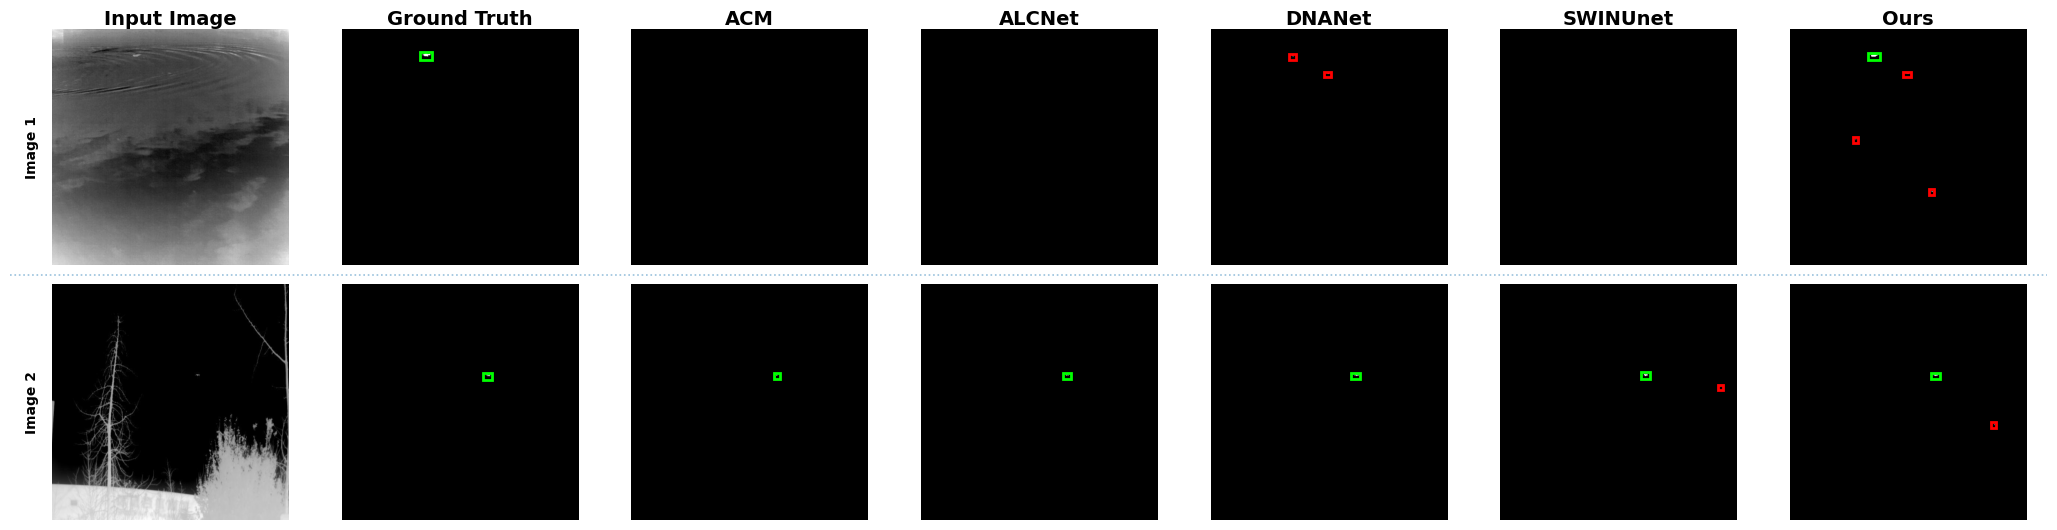

In [ ]:
compare_models_2d(
    image_tensors=image_tensors,
    mask_tensors=mask_tensors,
    model_paths=model_paths,
    model_names=model_names,
    model_channels=model_channels,
    device="cuda",
    num_images=2,
    threshold=0.5,
    match_distance=3,
    min_area=1,
    box_padding=5,
    show_probability=False
)

#FPS AND LATENCY

In [ ]:
def calculate_latency_fps(
    image_tensors,
    model_paths,
    model_names,
    model_channels,
    device="cuda",
    num_warmup=20,
    num_runs=100
):

    results = []

    # ==========================================================
    # LOOP THROUGH MODELS
    # ==========================================================
    for model_path, model_name, required_channels in zip(
        model_paths,
        model_names,
        model_channels
    ):

        # ======================================================
        # LOAD MODEL
        # ======================================================
        model = torch.jit.load(
            model_path,
            map_location=device
        )

        model.eval()


        # ======================================================
        # USE ONE TEST IMAGE
        # ======================================================
        image_tensor = image_tensors[0]

        # [1,H,W] -> [H,W]
        image = image_tensor[0]


        # ======================================================
        # PREPARE INPUT
        # ======================================================

        # 1-channel model
        if required_channels == 1:

            x_input = (
                image
                .unsqueeze(0)
                .unsqueeze(0)
                .to(device)
            )


        # 3-channel model
        elif required_channels == 3:

            image_3ch = (
                image
                .unsqueeze(0)
                .repeat(
                    3,
                    1,
                    1
                )
            )

            x_input = (
                image_3ch
                .unsqueeze(0)
                .to(device)
            )


        else:

            raise ValueError(
                f"Unsupported number of channels: "
                f"{required_channels}"
            )


        # ======================================================
        # WARM-UP
        # ======================================================
        # Important for accurate GPU timing
        with torch.no_grad():

            for _ in range(num_warmup):

                _ = model(x_input)


        if device.startswith("cuda"):
            torch.cuda.synchronize()


        # ======================================================
        # MEASURE LATENCY
        # ======================================================
        timings = []


        with torch.no_grad():

            for _ in range(num_runs):

                if device.startswith("cuda"):
                    torch.cuda.synchronize()

                start_time = time.perf_counter()


                # ----------------------------------------------
                # MODEL INFERENCE
                # ----------------------------------------------
                _ = model(x_input)


                if device.startswith("cuda"):
                    torch.cuda.synchronize()


                end_time = time.perf_counter()


                elapsed_time = (
                    end_time - start_time
                )

                timings.append(elapsed_time)


        # ======================================================
        # CALCULATE RESULTS
        # ======================================================

        # Average latency in seconds
        avg_latency_seconds = np.mean(timings)


        # Convert to milliseconds
        avg_latency_ms = (
            avg_latency_seconds * 1000
        )


        # FPS
        fps = (
            1.0 / avg_latency_seconds
        )


        # ======================================================
        # SAVE RESULT
        # ======================================================
        results.append(
            {
                "Model": model_name,
                "Latency (ms)": avg_latency_ms,
                "FPS": fps
            }
        )


        # ======================================================
        # PRINT
        # ======================================================
        print(
            f"{model_name:<20} | "
            f"Latency: {avg_latency_ms:.3f} ms | "
            f"FPS: {fps:.2f}"
        )


    return results

In [ ]:
results = calculate_latency_fps(image_tensors=image_tensors,model_paths=model_paths,model_names=model_names,model_channels=model_channels,
    device="cuda",
    num_warmup=20,
    num_runs=100
)

ACM                  | Latency: 9.169 ms | FPS: 109.06
ALCNet               | Latency: 15.302 ms | FPS: 65.35
DNANet               | Latency: 49.175 ms | FPS: 20.34
SWINUnet             | Latency: 18.615 ms | FPS: 53.72
Ours                 | Latency: 13.409 ms | FPS: 74.57


In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from scipy.ndimage import label
from matplotlib.patches import Rectangle


# ============================================================
# 1. GET CONNECTED COMPONENTS
# ============================================================
def get_components(binary_mask, min_area=1):

    """
    Extract connected components from a binary mask.

    Returns:
        centroid
        bounding box
        area
    """

    binary_mask = (binary_mask > 0).astype(np.uint8)

    # 8-connectivity
    structure = np.ones((3, 3), dtype=np.uint8)

    labeled_mask, num_components = label(
        binary_mask,
        structure=structure
    )

    components = []

    for component_id in range(1, num_components + 1):

        ys, xs = np.where(
            labeled_mask == component_id
        )

        # Ignore very small components if required
        if len(xs) < min_area:
            continue


        # ======================================================
        # CENTROID
        # ======================================================
        centroid_x = xs.mean()
        centroid_y = ys.mean()


        # ======================================================
        # BOUNDING BOX
        # ======================================================
        x_min = xs.min()
        x_max = xs.max()

        y_min = ys.min()
        y_max = ys.max()


        components.append(
            {
                "centroid": (
                    centroid_x,
                    centroid_y
                ),

                "bbox": (
                    x_min,
                    y_min,
                    x_max,
                    y_max
                ),

                "area": len(xs)
            }
        )


    return components



# ============================================================
# 2. MATCH PREDICTIONS TO GROUND TRUTH
# ============================================================
def match_predictions_to_gt(
    pred_components,
    gt_components,
    max_distance=3
):

    """
    Match predicted components with GT components
    based on centroid distance.

    Green box:
        Correct detection

    Red box:
        False alarm
    """

    matched_gt = set()

    results = []


    for pred_component in pred_components:

        pred_x, pred_y = pred_component["centroid"]

        best_distance = float("inf")
        best_gt_idx = None


        # ======================================================
        # FIND NEAREST UNUSED GT TARGET
        # ======================================================
        for gt_idx, gt_component in enumerate(gt_components):

            # Prevent one GT target from matching
            # multiple predictions
            if gt_idx in matched_gt:
                continue


            gt_x, gt_y = gt_component["centroid"]


            distance = np.sqrt(
                (pred_x - gt_x) ** 2
                +
                (pred_y - gt_y) ** 2
            )


            if distance < best_distance:

                best_distance = distance
                best_gt_idx = gt_idx


        # ======================================================
        # CORRECT DETECTION
        # ======================================================
        if (
            best_gt_idx is not None
            and
            best_distance <= max_distance
        ):

            matched_gt.add(best_gt_idx)

            results.append(
                {
                    "component": pred_component,
                    "status": "true",
                    "distance": best_distance
                }
            )


        # ======================================================
        # FALSE ALARM
        # ======================================================
        else:

            results.append(
                {
                    "component": pred_component,
                    "status": "false",
                    "distance": None
                }
            )


    return results



# ============================================================
# 3. DRAW BOUNDING BOX
# ============================================================
def draw_bbox(
    ax,
    bbox,
    color,
    padding=4,
    linewidth=2
):

    """
    Draw a bounding box around a target.
    """

    x_min, y_min, x_max, y_max = bbox


    # Add padding so very small IR targets
    # are easier to see
    new_x_min = x_min - padding
    new_y_min = y_min - padding


    width = (
        x_max
        - x_min
        + 2 * padding
        + 1
    )


    height = (
        y_max
        - y_min
        + 2 * padding
        + 1
    )


    rect = Rectangle(
        (new_x_min, new_y_min),
        width,
        height,
        linewidth=linewidth,
        edgecolor=color,
        facecolor="none"
    )


    ax.add_patch(rect)



# ============================================================
# 4. MAIN COMPARISON FUNCTION
# ============================================================
def compare_models_2d(
    image_tensors,
    mask_tensors,
    model_paths,
    model_names,
    model_channels,
    device="cuda",
    num_images=20,
    threshold=0.5,
    match_distance=3,
    min_area=1,
    box_padding=4,
    show_probability=False
):


    # ==========================================================
    # 1. LOAD ALL MODELS
    # ==========================================================
    models = []


    for path in model_paths:

        model = torch.jit.load(
            path,
            map_location=device
        )

        model.eval()

        models.append(model)



    # ==========================================================
    # 2. NUMBER OF IMAGES
    # ==========================================================
    num_images = min(
        num_images,
        len(image_tensors),
        len(mask_tensors)
    )



    # ==========================================================
    # 3. NUMBER OF COLUMNS
    # ==========================================================
    # Input + Ground Truth + all models
    num_cols = len(models) + 2



    # ==========================================================
    # 4. CREATE FIGURE
    # ==========================================================
    fig, axes = plt.subplots(
        num_images,
        num_cols,

        figsize=(
            3.0 * num_cols,
            2.5 * num_images
        ),

        squeeze=False
    )



    # ==========================================================
    # 5. LOOP THROUGH IMAGES
    # ==========================================================
    for row in range(num_images):


        image_tensor = image_tensors[row]
        mask_tensor = mask_tensors[row]


        # ======================================================
        # PREPARE INPUT IMAGE
        # ======================================================
        image = image_tensor[0]


        img = (
            image
            .detach()
            .cpu()
            .numpy()
        )



        # ======================================================
        # PREPARE GROUND TRUTH
        # ======================================================
        mask = (
            mask_tensor[0]
            .detach()
            .cpu()
            .numpy()
        )


        gt_binary = (
            mask > 0.5
        ).astype(np.uint8)



        # ======================================================
        # FIND GT TARGETS
        # ======================================================
        gt_components = get_components(
            gt_binary,
            min_area=min_area
        )



        # ======================================================
        # COLUMN 1: INPUT IMAGE
        # ======================================================
        ax = axes[row, 0]


        ax.imshow(
            img,
            cmap="gray"
        )


        ax.axis("off")



        # ======================================================
        # INPUT IMAGE TITLE
        # ======================================================
        if row == 0:

            ax.set_title(
                "Input Image",
                fontsize=14,
                fontweight="bold",
                pad=3
            )



        # ======================================================
        # IMAGE 1, IMAGE 2, IMAGE 3...
        # ======================================================
        ax.text(
            -0.055,
            0.5,
            f"Image {row + 1}",
            transform=ax.transAxes,
            fontsize=10,
            fontweight="bold",
            va="center",
            ha="right",
            rotation=90
        )



        # ======================================================
        # COLUMN 2: GROUND TRUTH
        # ======================================================
        ax = axes[row, 1]


        ax.imshow(
            gt_binary,
            cmap="gray",
            vmin=0,
            vmax=1
        )



        # ======================================================
        # DRAW GT BOUNDING BOXES
        # ======================================================
        for gt_component in gt_components:

            draw_bbox(
                ax,
                gt_component["bbox"],

                # Green box
                color="lime",

                padding=box_padding,
                linewidth=2
            )



        ax.axis("off")



        # ======================================================
        # GROUND TRUTH TITLE
        # ======================================================
        if row == 0:

            ax.set_title(
                "Ground Truth",
                fontsize=14,
                fontweight="bold",
                pad=3
            )



        # ======================================================
        # MODEL PREDICTIONS
        # ======================================================
        for model_idx, (
            model,
            required_channels
        ) in enumerate(
            zip(
                models,
                model_channels
            )
        ):


            # ==================================================
            # PREPARE MODEL INPUT
            # ==================================================

            # --------------------------------------------------
            # 1-CHANNEL MODEL
            # --------------------------------------------------
            if required_channels == 1:

                x_input = (
                    image
                    .unsqueeze(0)
                    .unsqueeze(0)
                    .to(device)
                )



            # --------------------------------------------------
            # 3-CHANNEL MODEL
            # --------------------------------------------------
            elif required_channels == 3:

                image_3ch = (
                    image
                    .unsqueeze(0)
                    .repeat(
                        3,
                        1,
                        1
                    )
                )


                x_input = (
                    image_3ch
                    .unsqueeze(0)
                    .to(device)
                )



            else:

                raise ValueError(
                    f"Unsupported number of channels: "
                    f"{required_channels}"
                )



            # ==================================================
            # FORWARD PASS
            # ==================================================
            with torch.no_grad():

                output = model(
                    x_input
                )



            # ==================================================
            # HANDLE MULTIPLE MODEL OUTPUTS
            # ==================================================
            if isinstance(
                output,
                (tuple, list)
            ):

                # Assume first output is main prediction
                output = output[0]



            # ==================================================
            # LOGITS -> PROBABILITY
            # ==================================================
            pred_probability = torch.sigmoid(
                output
            )



            # ==================================================
            # REMOVE BATCH / CHANNEL DIMENSIONS
            # ==================================================

            # [B,1,H,W] -> [H,W]
            if pred_probability.ndim == 4:

                pred_probability = pred_probability[
                    0,
                    0
                ]


            # [B,H,W] -> [H,W]
            elif pred_probability.ndim == 3:

                pred_probability = pred_probability[
                    0
                ]



            pred_probability = (
                pred_probability
                .detach()
                .cpu()
                .numpy()
            )



            # ==================================================
            # CREATE BINARY PREDICTION
            # ==================================================
            pred_binary = (
                pred_probability >= threshold
            ).astype(np.uint8)



            # ==================================================
            # FIND PREDICTED COMPONENTS
            # ==================================================
            pred_components = get_components(
                pred_binary,
                min_area=min_area
            )



            # ==================================================
            # MATCH WITH GROUND TRUTH
            # ==================================================
            prediction_results = match_predictions_to_gt(
                pred_components,
                gt_components,
                max_distance=match_distance
            )



            # ==================================================
            # DISPLAY MODEL PREDICTION
            # ==================================================
            ax = axes[
                row,
                model_idx + 2
            ]



            # --------------------------------------------------
            # SHOW PROBABILITY MAP
            # --------------------------------------------------
            if show_probability:

                ax.imshow(
                    pred_probability,
                    cmap="gray",
                    vmin=0,
                    vmax=1
                )



            # --------------------------------------------------
            # SHOW BINARY MASK
            # --------------------------------------------------
            else:

                ax.imshow(
                    pred_binary,
                    cmap="gray",
                    vmin=0,
                    vmax=1
                )



            # ==================================================
            # DRAW CORRECT DETECTIONS / FALSE ALARMS
            # ==================================================
            for result in prediction_results:

                component = result["component"]



                # ==============================================
                # CORRECT TARGET
                # GREEN BOX
                # ==============================================
                if result["status"] == "true":

                    draw_bbox(
                        ax,
                        component["bbox"],
                        color="lime",
                        padding=box_padding,
                        linewidth=2
                    )



                # ==============================================
                # FALSE ALARM
                # RED BOX
                # ==============================================
                else:

                    draw_bbox(
                        ax,
                        component["bbox"],
                        color="red",
                        padding=box_padding,
                        linewidth=2
                    )



            ax.axis("off")



            # ==================================================
            # MODEL COLUMN TITLE
            # ==================================================
            if row == 0:

                ax.set_title(
                    model_names[model_idx],
                    fontsize=14,
                    fontweight="bold",
                    pad=3
                )



    # ==========================================================
    # 6. FIGURE SPACING
    # ==========================================================
    plt.subplots_adjust(

        # Space for Image 1 / Image 2 labels
        left=0.035,

        right=0.995,

        bottom=0.008,

        # No legend now, so plots can move higher
        top=0.99,

        # Distance between model columns
        wspace=0.04,

        # Distance between image rows
        hspace=0.08
    )



    # ==========================================================
    # 7. DOTTED SEPARATORS BETWEEN IMAGES
    # ==========================================================
    plot_bottom = 0.008
    plot_top = 0.99


    plot_height = (
        plot_top
        -
        plot_bottom
    )


    row_height = (
        plot_height
        /
        num_images
    )



    for row in range(
        1,
        num_images
    ):


        y_line = (
            plot_top
            -
            row * row_height
        )


        separator = plt.Line2D(

            [0.025, 0.995],

            [y_line, y_line],

            transform=fig.transFigure,

            linestyle=":",

            linewidth=1.2,

            alpha=0.45
        )


        fig.add_artist(
            separator
        )



    # ==========================================================
    # 8. SHOW
    # ==========================================================
    plt.show()

#ROC CURVE

In [ ]:
n = len(testloader)

image_tensors = []
mask_tensors = []

for _ in range(n):
    random_index = _
    random_sample = testloader.dataset[random_index]

    image_tensors.append(random_sample[0])
    mask_tensors.append(random_sample[1])

In [ ]:
len(image_tensors)

2

In [ ]:
def compare_models_roc(image_tensors, mask_tensors, model_paths, model_names, model_channels, device="cuda"):

    models = []
    for path in model_paths:
        model = torch.jit.load(path, map_location=device)
        model.eval()
        models.append(model)

    all_gt = []

    for mask_tensor in mask_tensors:
        mask = mask_tensor[0].detach().cpu().numpy()
        all_gt.append((mask > 0.5).astype(np.uint8).flatten())

    all_gt = np.concatenate(all_gt)

    plt.figure(figsize=(7, 6))

    auc_scores = {}

    for model, model_name, required_channels in zip(models, model_names, model_channels):

        all_probabilities = []

        with torch.no_grad():

            for image_tensor in image_tensors:

                image = image_tensor[0]

                if required_channels == 1:
                    x_input = image.unsqueeze(0).unsqueeze(0).to(device)

                elif required_channels == 3:
                    x_input = image.unsqueeze(0).repeat(3, 1, 1).unsqueeze(0).to(device)

                else:
                    raise ValueError(f"Unsupported number of channels: {required_channels}")

                output = model(x_input)

                if isinstance(output, (tuple, list)):
                    output = output[0]

                probability = torch.sigmoid(output)

                if probability.ndim == 4:
                    probability = probability[0, 0]
                elif probability.ndim == 3:
                    probability = probability[0]

                all_probabilities.append(probability.detach().cpu().numpy().flatten())

        all_probabilities = np.concatenate(all_probabilities)

        fpr, tpr, thresholds = roc_curve(all_gt, all_probabilities)

        plt.plot(fpr,tpr,linewidth=2,label=f"{model_name}")


    plt.xlabel("Fa", fontsize=12)
    plt.ylabel("Pd", fontsize=12)
    plt.legend(loc="lower right")
    plt.xticks(np.arange(0, 1.01, 0.1))
    plt.yticks(np.arange(0, 1.01, 0.1))
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


    return auc_scores

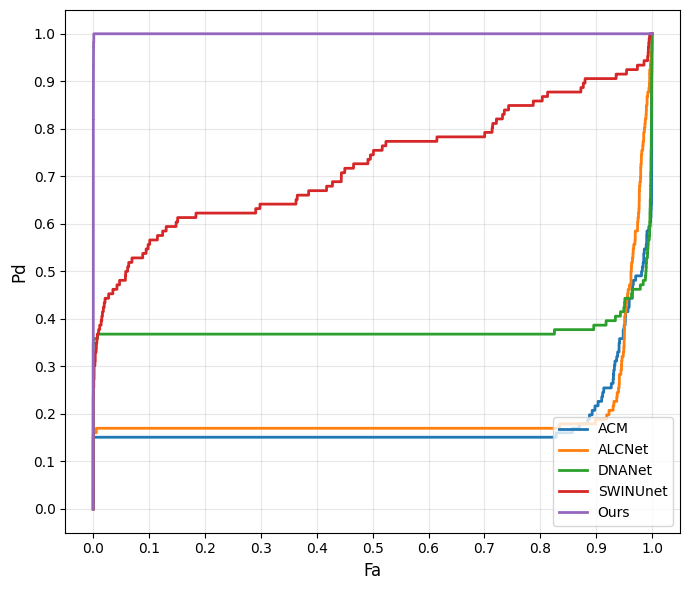

{}

In [ ]:
compare_models_roc(image_tensors,mask_tensors,model_paths,model_names,model_channels,device="cuda")